<a href="https://colab.research.google.com/github/deekshamanchikatla/Calculator-Java/blob/main/Performance_Analysis_of_CNN_Architectures_for_Multiclass_Image_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Cell 1: Import libraries

In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

from tensorflow.keras import layers, models
from sklearn.metrics import classification_report

Cell 2: Load CIFAR-10 dataset

In [3]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

print("Training images:", x_train.shape)
print("Testing images:", x_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2336s 14us/step
Training images: (50000, 32, 32, 3)
Testing images: (10000, 32, 32, 3)


Cell 3: Normalize images

In [4]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

y_train = y_train.flatten()
y_test = y_test.flatten()

print("Normalization completed")

Normalization completed


Cell 4: Display sample images

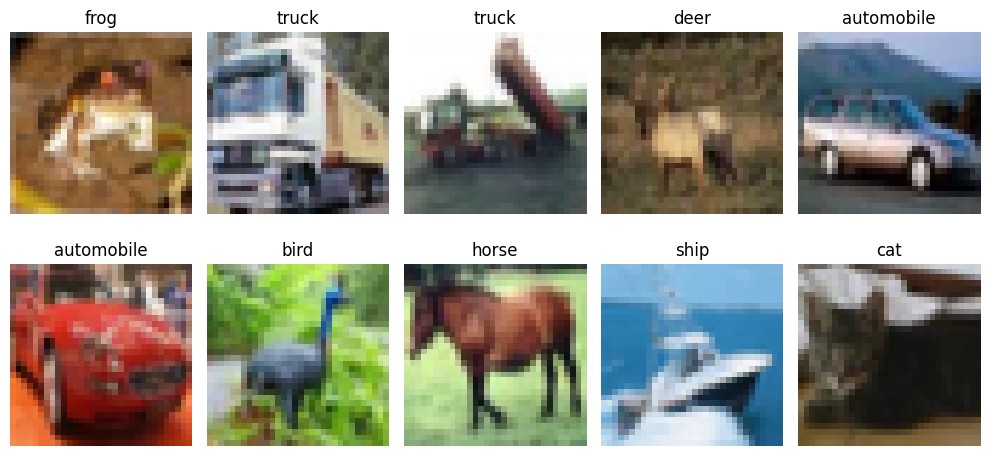

In [5]:
class_names = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

Cell 5: Create three CNN architectures

In [6]:
def build_cnn(model_type):
    model = models.Sequential()
    model.add(layers.Input(shape=(32, 32, 3)))

    if model_type == "Simple CNN":
        model.add(layers.Conv2D(32, 3, activation='relu'))
        model.add(layers.MaxPooling2D())
        model.add(layers.Flatten())
        model.add(layers.Dense(64, activation='relu'))

    elif model_type == "Deep CNN":
        model.add(layers.Conv2D(32, 3, padding='same',
                                activation='relu'))
        model.add(layers.Conv2D(32, 3, activation='relu'))
        model.add(layers.MaxPooling2D())

        model.add(layers.Conv2D(64, 3, padding='same',
                                activation='relu'))
        model.add(layers.Conv2D(64, 3, activation='relu'))
        model.add(layers.MaxPooling2D())

        model.add(layers.Flatten())
        model.add(layers.Dense(128, activation='relu'))
        model.add(layers.Dropout(0.3))

    else:  # CNN with Batch Normalization
        model.add(layers.Conv2D(32, 3, padding='same'))
        model.add(layers.BatchNormalization())
        model.add(layers.Activation('relu'))
        model.add(layers.MaxPooling2D())

        model.add(layers.Conv2D(64, 3, padding='same'))
        model.add(layers.BatchNormalization())
        model.add(layers.Activation('relu'))
        model.add(layers.MaxPooling2D())

        model.add(layers.Conv2D(128, 3, padding='same'))
        model.add(layers.BatchNormalization())
        model.add(layers.Activation('relu'))
        model.add(layers.GlobalAveragePooling2D())

        model.add(layers.Dense(64, activation='relu'))
        model.add(layers.Dropout(0.3))

    model.add(layers.Dense(10, activation='softmax'))

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

Cell 6: Train and compare the models

In [8]:
results = []
trained_models = {}
histories = {}

for name in ["Simple CNN", "Deep CNN", "Batch Normalization CNN"]:

    print("\nTraining:", name)

    model = build_cnn(name)
    start = time.time()

    history = model.fit(
        x_train, y_train,
        epochs=5,
        batch_size=64,
        validation_split=0.1,
        verbose=1
    )

    training_time = time.time() - start

    test_loss, test_accuracy = model.evaluate(
        x_test, y_test, verbose=0
    )

    results.append({
        "Architecture": name,
        "Test Accuracy (%)": round(test_accuracy * 100, 2),
        "Test Loss": round(test_loss, 4),
        "Training Time (seconds)": round(training_time, 2)
    })

    trained_models[name] = model
    histories[name] = history

print("Training completed!")


Training: Simple CNN
Epoch 1/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 31s 42ms/step - accuracy: 0.4513 - loss: 1.5325 - val_accuracy: 0.5206 - val_loss: 1.3644
Epoch 2/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 41s 42ms/step - accuracy: 0.5651 - loss: 1.2323 - val_accuracy: 0.5622 - val_loss: 1.2648
Epoch 3/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.6044 - loss: 1.1243 - val_accuracy: 0.6020 - val_loss: 1.1524
Epoch 4/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.6373 - loss: 1.0418 - val_accuracy: 0.6196 - val_loss: 1.0890
Epoch 5/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 30s 43ms/step - accuracy: 0.6562 - loss: 0.9873 - val_accuracy: 0.6130 - val_loss: 1.1132

Training: Deep CNN
Epoch 1/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 172s 242ms/step - accuracy: 0.4388 - loss: 1.5450 - val_accuracy: 0.5636 - val_loss: 1.2524
Epoch 2/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 162s 231ms/step - accuracy: 0.5909 - loss: 1.1493 - val_accuracy: 0.6622 - val_loss: 0.9613
Epoch 3/5
704/704 ━━━━━━━━━━━━━━━━━━━━ 165s 234ms/s

Cell 7: Display comparison table

In [9]:
results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

           Architecture  Test Accuracy (%)  Test Loss  Training Time (seconds)
             Simple CNN              59.97     1.1439                   161.44
               Deep CNN              70.55     0.8689                   870.00
Batch Normalization CNN              52.28     1.3243                   679.96


Cell 8: Plot accuracy comparison

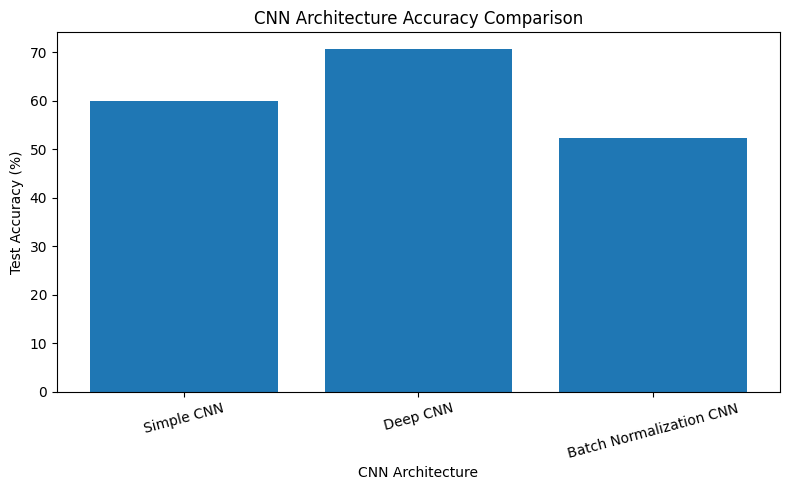

In [10]:
plt.figure(figsize=(8, 5))

plt.bar(
    results_df["Architecture"],
    results_df["Test Accuracy (%)"]
)

plt.title("CNN Architecture Accuracy Comparison")
plt.xlabel("CNN Architecture")
plt.ylabel("Test Accuracy (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

Cell 9: Plot training and validation accuracy

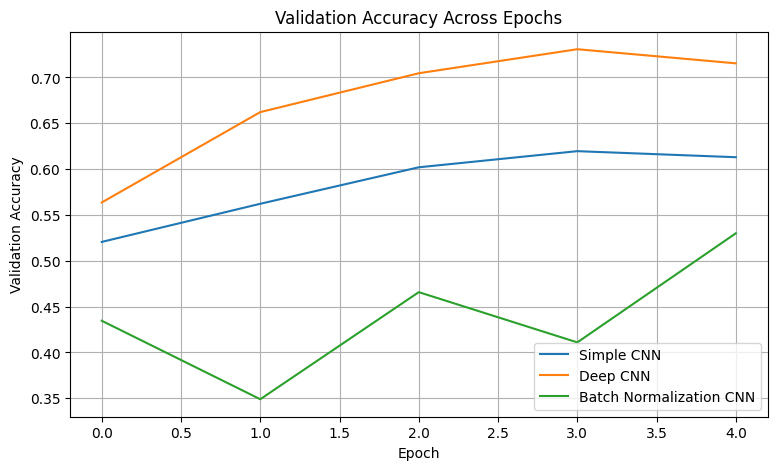

In [11]:
plt.figure(figsize=(9, 5))

for name, history in histories.items():
    plt.plot(history.history['val_accuracy'], label=name)

plt.title("Validation Accuracy Across Epochs")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

Cell 10: Classification report

In [12]:
best_name = results_df.loc[
    results_df["Test Accuracy (%)"].idxmax(),
    "Architecture"
]

best_model = trained_models[best_name]

y_pred = np.argmax(
    best_model.predict(x_test, verbose=0),
    axis=1
)

print("Best model:", best_name)

print(classification_report(
    y_test,
    y_pred,
    labels=list(range(10)),
    target_names=class_names,
    zero_division=0
))

Best model: Deep CNN
              precision    recall  f1-score   support

    airplane       0.59      0.86      0.70      1000
  automobile       0.84      0.84      0.84      1000
        bird       0.62      0.56      0.59      1000
         cat       0.57      0.53      0.55      1000
        deer       0.61      0.72      0.66      1000
         dog       0.82      0.43      0.56      1000
        frog       0.80      0.74      0.77      1000
       horse       0.81      0.70      0.75      1000
        ship       0.71      0.89      0.79      1000
       truck       0.80      0.80      0.80      1000

    accuracy                           0.71     10000
   macro avg       0.72      0.71      0.70     10000
weighted avg       0.72      0.71      0.70     10000



Cell 11: Predict a sample image

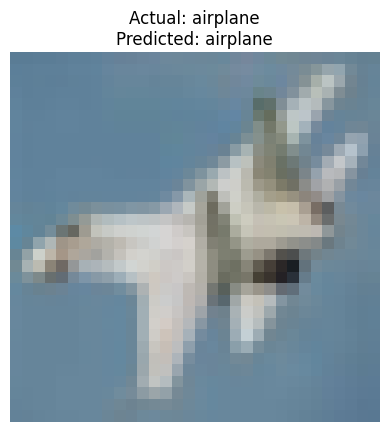

In [13]:
index = 10

prediction = best_model.predict(
    x_test[index:index+1],
    verbose=0
)

predicted_class = np.argmax(prediction)

plt.imshow(x_test[index])
plt.title(
    f"Actual: {class_names[y_test[index]]}\n"
    f"Predicted: {class_names[predicted_class]}"
)
plt.axis("off")
plt.show()

Cell 12: Save the best model

In [14]:
best_model.save("best_cifar10_cnn.keras")
print("Model saved successfully!")

Model saved successfully!
